<a href="https://colab.research.google.com/github/Veniveni123/CSA47-DEEP-LEARNING/blob/main/LAB%2021-30/Experiment%2028%3A%20Deep%20Boltzmann%20Machine%20Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Two-Layer DBM Reconstruction MSE: 0.0803


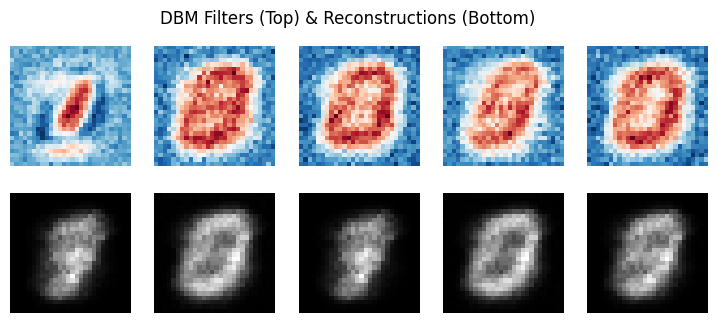

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

np.random.seed(42)

(X_tr, _), (X_te, _) = keras.datasets.mnist.load_data()
X_train = (X_tr[:1000].reshape(-1, 784) > 127).astype(np.float32)
X_test = (X_te[:100].reshape(-1, 784) > 127).astype(np.float32)
sig = lambda x: 1.0 / (1.0 + np.exp(-np.clip(x, -20, 20)))

W1 = np.random.normal(0, 0.01, (784, 64))
W2 = np.random.normal(0, 0.01, (64, 32))
a, b1, b2 = np.zeros(784), np.zeros(64), np.zeros(32)

def mf(v):
    m1 = sig(v @ W1 + b1)
    m2 = sig(m1 @ W2 + b2)
    for _ in range(3):
        m1 = sig(v @ W1 + m2 @ W2.T + b1)
        m2 = sig(m1 @ W2 + b2)
    return m1, m2

for _ in range(6):
    for i in range(0, len(X_train), 50):
        v0 = X_train[i:i+50]
        m1, m2 = mf(v0)
        pv1 = sig((np.random.rand(*m1.shape) < m1) @ W1.T + a)
        v1 = (np.random.rand(*pv1.shape) < pv1).astype(np.float32)
        nm1, nm2 = mf(v1)
        W1 += 0.05 * ((v0.T @ m1) - (v1.T @ nm1)) / len(v0)
        W2 += 0.05 * ((m1.T @ m2) - (nm1.T @ nm2)) / len(v0)
        a += 0.05 * np.mean(v0 - pv1, axis=0)
        b1 += 0.05 * np.mean(m1 - nm1, axis=0)
        b2 += 0.05 * np.mean(m2 - nm2, axis=0)

dbm_rec = sig(mf(X_test)[0] @ W1.T + a)
print("Two-Layer DBM Reconstruction MSE:", round(float(np.mean((X_test - dbm_rec) ** 2)), 4))

fig, axes = plt.subplots(2, 5, figsize=(9, 3.5))
for i in range(5):
    axes[0, i].imshow(W1[:, i].reshape(28, 28), cmap='RdBu_r'); axes[0, i].axis('off')
    axes[1, i].imshow(dbm_rec[i].reshape(28, 28), cmap='gray'); axes[1, i].axis('off')
plt.suptitle("DBM Filters (Top) & Reconstructions (Bottom)")
plt.show()